In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics import tsaplots
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from arch import arch_model
import warnings

In [95]:
df = pd.read_parquet("../DATOS/TRANSFORMADOS/df_diario.parquet")

In [96]:
df

Ticker,AAPL,AMGN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,DOW,...,KO,MCD,MMM,MRK,MSFT,NKE,PG,TRV,UNH,V
Atributo,open,open,open,open,open,open,open,open,open,open,...,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close
2018-06-06,45.803260,147.060853,90.831614,348.858528,131.109462,133.374320,35.413420,90.796595,96.121399,NaN,...,33.519558,133.685410,128.639145,45.619328,94.516289,66.114006,59.448215,107.609100,215.247879,128.590698
2018-06-07,45.927449,148.240513,92.139591,358.040544,134.061884,134.585641,35.801869,91.843793,97.898584,NaN,...,33.504131,139.530716,129.402634,45.663540,93.031555,66.122833,60.575588,109.097145,215.533554,126.288330
2018-06-08,45.176401,148.579864,92.003343,354.325406,133.276850,130.763026,35.219198,93.746452,98.071492,NaN,...,33.897491,139.061371,130.361816,46.098148,93.723198,66.246681,61.710991,110.400223,217.005142,127.137596
2018-06-11,45.262742,148.781859,91.903427,357.078069,132.355285,132.927524,35.300123,93.488335,99.839069,NaN,...,34.036316,137.069077,129.434250,45.913998,93.188309,65.972466,61.990837,109.710854,219.688721,126.354439
2018-06-12,45.272204,148.886901,92.194088,357.309054,133.703498,133.999842,35.348680,94.129931,100.607582,NaN,...,34.252262,137.266632,129.308029,45.995026,93.428078,65.707161,61.758949,108.937386,219.515579,127.250839
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-02,200.279999,285.640015,292.350006,210.979996,346.470001,263.109985,62.730000,138.490005,112.680000,27.660000,...,69.110367,303.118408,143.085358,72.623184,457.448090,59.296558,160.815430,269.972046,292.876587,361.784912
2025-06-03,201.350006,285.519989,295.200012,212.000000,346.000000,262.000000,63.799999,137.649994,112.730003,27.200001,...,68.304070,302.837311,144.776199,73.470856,458.438263,60.067020,159.924057,269.708252,289.512634,362.319702
2025-06-04,202.910004,290.190002,297.809998,214.770004,350.299988,264.190002,64.660004,139.419998,113.860001,27.850000,...,68.505646,302.042389,143.486099,74.547112,459.329468,60.452251,159.061401,265.595276,288.705292,364.438995


In [97]:
df_filtrado = df[['CAT', 'GS', 'MSFT']].xs("close",level=1,axis=1)
df_filtrado

Ticker,CAT,GS,MSFT
2018-06-06,133.549899,197.883033,95.450608
2018-06-07,133.362172,198.922596,93.951188
2018-06-08,132.534484,198.871472,94.649675
2018-06-11,133.392044,199.885470,94.109517
2018-06-12,135.358899,198.496548,94.351654
...,...,...,...
2025-06-02,344.670013,598.719971,461.970001
2025-06-03,349.399994,603.830017,462.970001
2025-06-04,349.329987,599.210022,463.869995
2025-06-05,348.959991,605.880005,467.679993


In [98]:
CAT = df_filtrado["CAT"]
GS = df_filtrado["GS"]
MSFT = df_filtrado["MSFT"]

<Axes: >

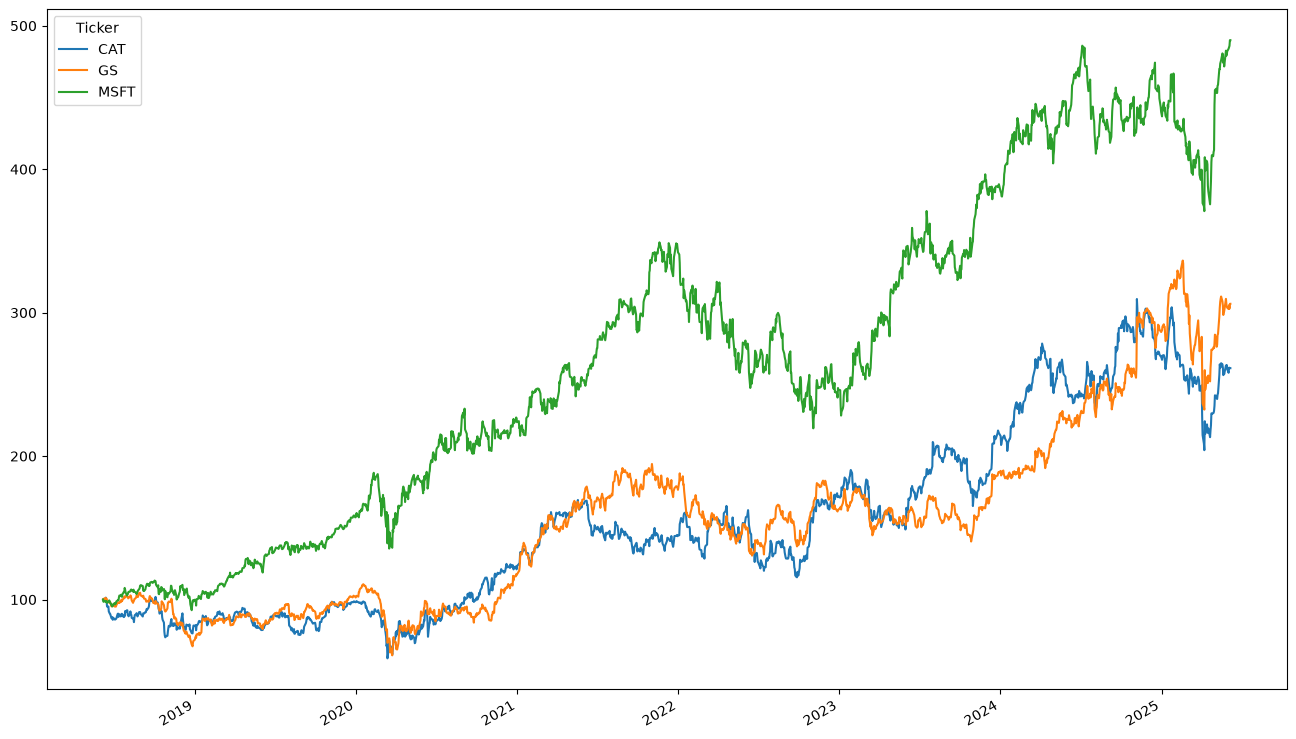

In [99]:
precios_norm = (df_filtrado / df_filtrado.iloc[0]) * 100

precios_norm.plot(figsize=(16,10))

#### Pasos a seguir

Analizar los componentes de la serie y tratarla como es debida para convertirla en estacionaria.

Si estacionalidad -> descomposición estacional
Si no estacionalidad -> tratar tendencia

Si tras tratar la serie existe heterocedasticidad -> Modelizar la volatilidad (ARCH o GARCH)

En caso de modelizar la volatilidad, se han mirado las autocorrelaciones y autocorrelaciones parciales sobre los rendimientos del activo al cuadrado. Sobre los resultados mostrados en las gráficas ACF y PACF se han decidido los parámetros con los que tratar de ajustar los ARCH y GARCH.


Para admitir un modelo, debe de cumplir con los siguientes puntos:
- Parámetros de modelo significativos
- El residuo post-modelo es homocedástico (ya no queda volatilidad)

In [100]:
def test_estacionariedad_y_het(series, lags=None):
    series = series.dropna()
    
    resultados = {}
    
    # 1. ADF
    adf_stat, adf_p, _, _, _, _ = adfuller(series, autolag='AIC')
    resultados['ADF'] = {
        'Estadístico': adf_stat,
        'p-value': adf_p,
        'Estacionariedad (0.05)': adf_p < 0.05
    }
    
    # 2. KPSS 
    kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')
    resultados['KPSS'] = {
        'Estadístico': kpss_stat,
        'p-value': kpss_p,
        'Estacionariedad (0.05)': kpss_p > 0.05
    }
    
    # 3. ARCH
    arch_stat, arch_p, _, _ = het_arch(series, nlags=lags)
    resultados['ARCH_Heteroskedasticity'] = {
        'Estadístico': arch_stat,
        'p-value': arch_p,
        'Estacionariedad (0.05)': arch_p < 0.05
    }
    
    return pd.DataFrame(resultados).T

In [125]:
def evaluate_volatility_models(returns, max_arch_p=4):
    warnings.simplefilter('ignore', FutureWarning)
    results = []
    
    COL_MODEL = 'Modelo'
    COL_SIG = 'Todos los Parametros Significativos (<0.05)'
    COL_ARCH_P = 'ARCH-LM P-value'
    COL_HOMO = 'Homocedastica (>0.05)'
    COL_PVALS = 'P-values de los Parametros del Modelo'
    
    for p in range(1, max_arch_p + 1):
        model = arch_model(returns, vol='ARCH', p=p, rescale=False)
        res = model.fit(disp='off')
        
        pvals = res.pvalues
        all_sig = bool(all(pvals < 0.05))
        pvals_str = ", ".join([f"{idx}: {val:.4f}" for idx, val in pvals.items()])
        
        std_resid = res.std_resid.dropna()
        _, arch_lm_pval, _, _ = het_arch(std_resid, nlags=5)
        lm_passed = bool(arch_lm_pval > 0.05)
        
        results.append({
            COL_MODEL: f'ARCH({p})',
            COL_SIG: all_sig,
            COL_ARCH_P: round(arch_lm_pval, 4),
            COL_HOMO: lm_passed,
            COL_PVALS: pvals_str
        })
        
    garch_configs = [(1, 1), (1, 2), (2, 1), (2, 2)]
    for p, q in garch_configs:
        model = arch_model(returns, vol='GARCH', p=p, q=q, rescale=False, dist="normal", mean="Constant")
        res = model.fit(disp='off')
        
        pvals = res.pvalues
        all_sig = bool(all(pvals < 0.05))
        pvals_str = ", ".join([f"{idx}: {val:.4f}" for idx, val in pvals.items()])
        
        std_resid = res.std_resid.dropna()
        _, arch_lm_pval, _, _ = het_arch(std_resid, nlags=5)
        lm_passed = bool(arch_lm_pval > 0.05)
        
        results.append({
            COL_MODEL: f'GARCH({p},{q})',
            COL_SIG: all_sig,
            COL_ARCH_P: round(arch_lm_pval, 4),
            COL_HOMO: lm_passed,
            COL_PVALS: pvals_str
        })
        
    return pd.DataFrame(results)

## Tratamiento de las series temporales

### CAT (Caterpillar)

<Axes: >

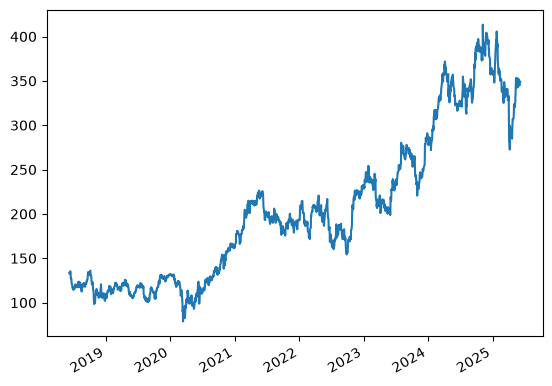

In [102]:
CAT.plot()

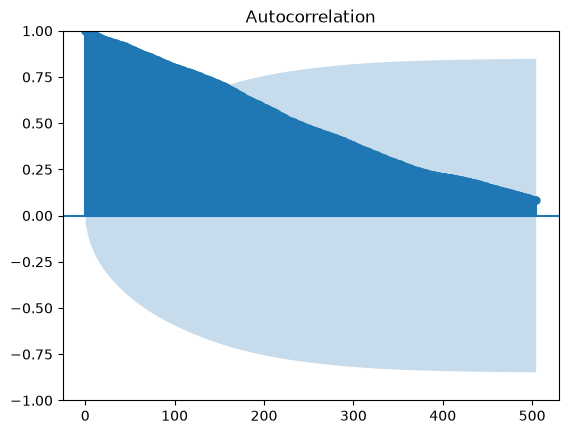

In [103]:
tsaplots.plot_acf(CAT, lags=504);

Al no descubrir ninguna estacionalidad, quitaremos solamente la tendencia y observaremos la homocedasticidad. Al tratarse de una serie financiera, y al poder diferenciar la serie para restarle la tendencia; se decide trabajar sobre los retornos. Los retornos o rentabilidades son un resultado similar a la diferenciación, además de ser el estándar del sector para tratar las series temporales, no sobre los precios absolutos.

In [104]:
CAT_r = CAT.pct_change().dropna()*100

<Axes: >

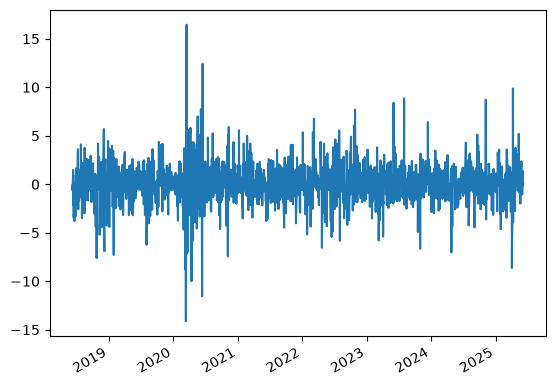

In [105]:
CAT_r.plot()

In [106]:
test_estacionariedad_y_het(CAT_r)

C:\Users\Markel\AppData\Local\Temp\ipykernel_2060\3844326302.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, _, _, _, _ = adfuller(series, autolag='AIC')
C:\Users\Markel\AppData\Local\Temp\ipykernel_2060\3844326302.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')
C:\Users\Markel\AppData\Local\Temp\ipykernel_2060\3844326302.py:15: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` 

,Estadístico,p-value,Estacionariedad (0.05)
ADF,-15.392905,0.0,True
KPSS,0.060526,0.1,True
ARCH_Heteroskedasticity,234.741924,0.0,True


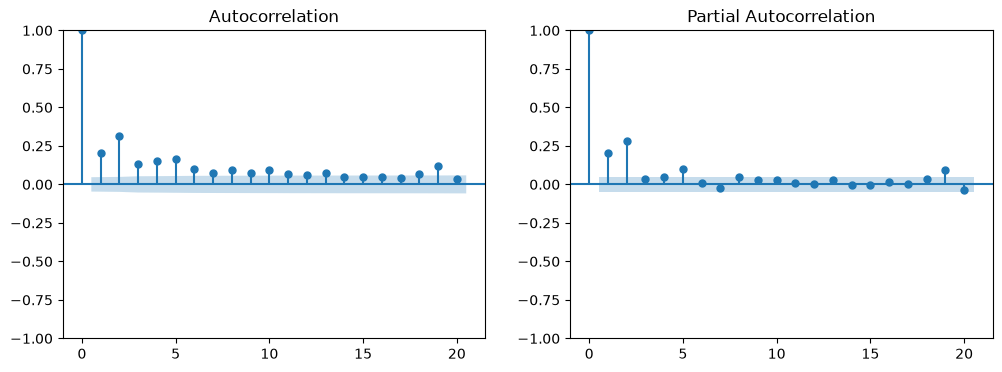

In [107]:
CAT_sq = CAT_r ** 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tsaplots.plot_acf(CAT_sq, lags=20, ax=ax[0])
tsaplots.plot_pacf(CAT_sq, lags=20, ax=ax[1])
plt.show()

In [126]:
tabla_resumen = evaluate_volatility_models(CAT_r, max_arch_p=2)
print(tabla_resumen.to_string(index=False))

    Modelo  Todos los Parametros Significativos (<0.05)  ARCH-LM P-value  Homocedastica (>0.05)                                                           P-values de los Parametros del Modelo
   ARCH(1)                                        False           0.0000                  False                                                     mu: 0.5910, omega: 0.0000, alpha[1]: 0.0045
   ARCH(2)                                        False           0.0000                  False                                   mu: 0.1569, omega: 0.0000, alpha[1]: 0.0009, alpha[2]: 0.0012
GARCH(1,1)                                        False           0.5888                   True                                    mu: 0.0983, omega: 0.0053, alpha[1]: 0.0008, beta[1]: 0.0000
GARCH(1,2)                                        False           0.5813                   True                   mu: 0.1040, omega: 0.0060, alpha[1]: 0.0016, beta[1]: 0.0176, beta[2]: 0.6621
GARCH(2,1)                              

### GS (Goldman Sachs)

<Axes: >

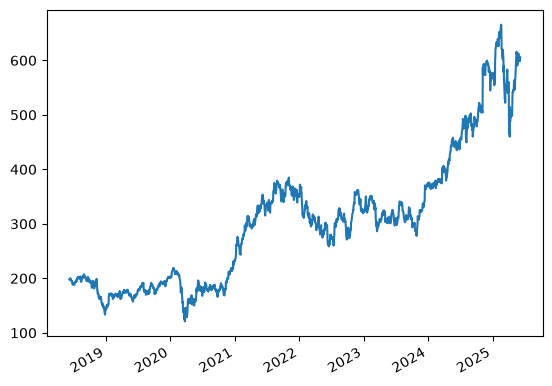

In [109]:
GS.plot()

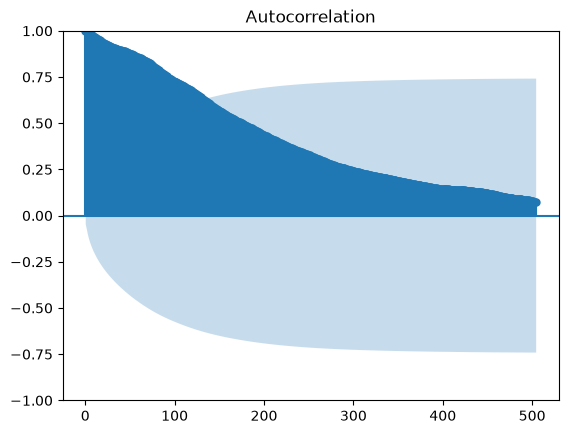

In [110]:
tsaplots.plot_acf(GS, lags=504);

Al no descubrir ninguna estacionalidad, quitaremos solamente la tendencia y observaremos la homocedasticidad. Al tratarse de una serie financiera, y al poder diferenciar la serie para restarle la tendencia; se decide trabajar sobre los retornos. Los retornos o rentabilidades son un resultado similar a la diferenciación, además de ser el estándar del sector para tratar las series temporales, no sobre los precios absolutos.

In [111]:
GS_r = GS.pct_change().dropna()*100

<Axes: >

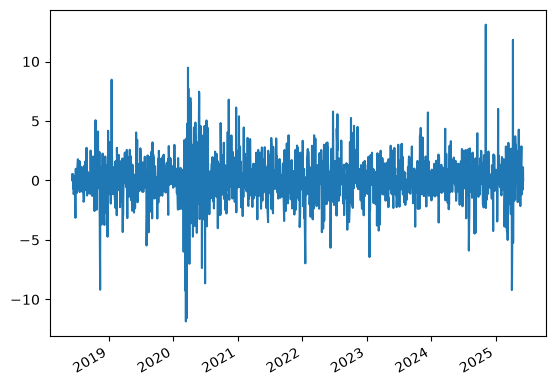

In [112]:
GS_r.plot()

In [113]:
test_estacionariedad_y_het(GS_r)

C:\Users\Markel\AppData\Local\Temp\ipykernel_2060\3844326302.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')


,Estadístico,p-value,Estacionariedad (0.05)
ADF,-40.299486,0.0,True
KPSS,0.102191,0.1,True
ARCH_Heteroskedasticity,202.798468,0.0,True


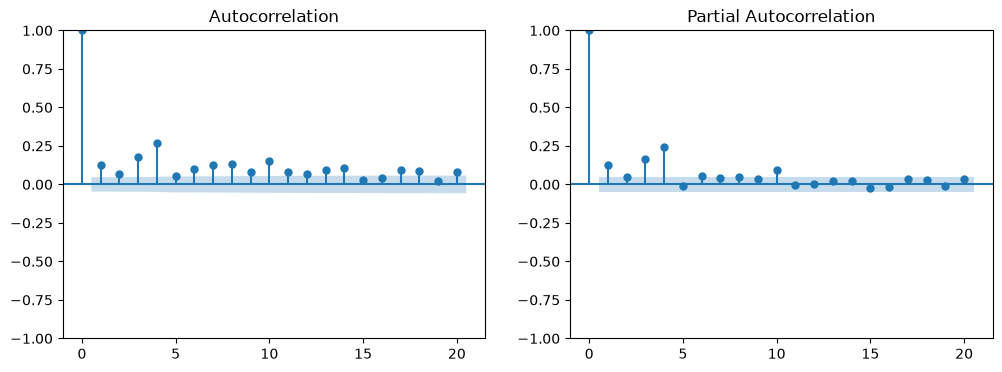

In [114]:
GS_sq = GS_r ** 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tsaplots.plot_acf(GS_sq, lags=20, ax=ax[0])
tsaplots.plot_pacf(GS_sq, lags=20, ax=ax[1])
plt.show()

In [127]:
tabla_resumen = evaluate_volatility_models(GS_r, max_arch_p=4)
print(tabla_resumen.to_string(index=False))

    Modelo  Todos los Parametros Significativos (<0.05)  ARCH-LM P-value  Homocedastica (>0.05)                                                             P-values de los Parametros del Modelo
   ARCH(1)                                         True           0.0000                  False                                                       mu: 0.0185, omega: 0.0000, alpha[1]: 0.0016
   ARCH(2)                                         True           0.0000                  False                                     mu: 0.0232, omega: 0.0000, alpha[1]: 0.0034, alpha[2]: 0.0479
   ARCH(3)                                        False           0.0009                  False                   mu: 0.0079, omega: 0.0000, alpha[1]: 0.0021, alpha[2]: 0.1642, alpha[3]: 0.0025
   ARCH(4)                                        False           0.9334                   True mu: 0.0135, omega: 0.0000, alpha[1]: 0.0062, alpha[2]: 0.1533, alpha[3]: 0.0108, alpha[4]: 0.0018
GARCH(1,1)                    

### MSFT (Microsoft)

<Axes: >

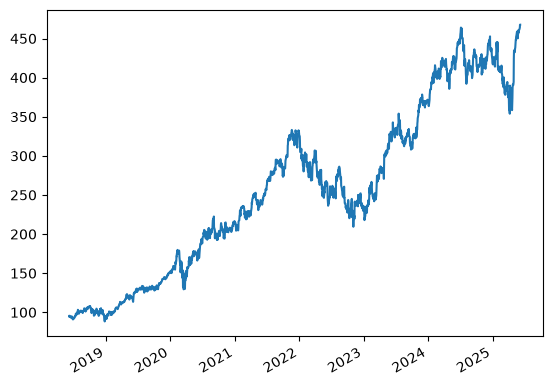

In [116]:
MSFT.plot()

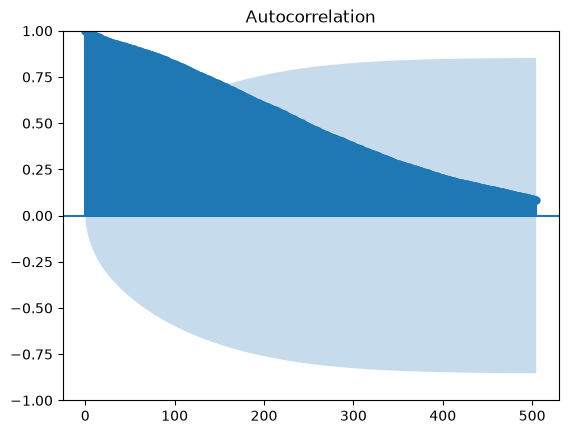

In [117]:
tsaplots.plot_acf(MSFT, lags=504);

Al no descubrir ninguna estacionalidad, quitaremos solamente la tendencia y observaremos la homocedasticidad. Al tratarse de una serie financiera, y al poder diferenciar la serie para restarle la tendencia; se decide trabajar sobre los retornos. Los retornos o rentabilidades son un resultado similar a la diferenciación, además de ser el estándar del sector para tratar las series temporales, no sobre los precios absolutos.

In [118]:
MSFT_r = MSFT.pct_change().dropna()*100

<Axes: >

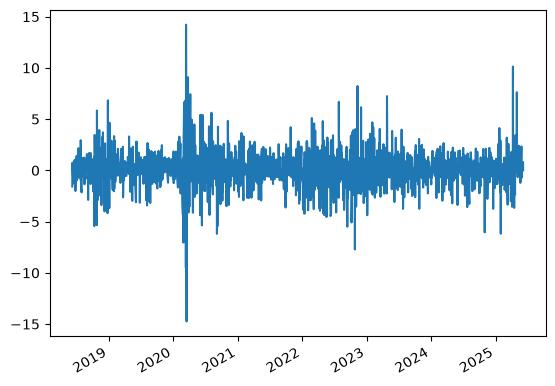

In [119]:
MSFT_r.plot()

In [120]:
test_estacionariedad_y_het(MSFT_r)

C:\Users\Markel\AppData\Local\Temp\ipykernel_2060\3844326302.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')


,Estadístico,p-value,Estacionariedad (0.05)
ADF,-13.402207,0.0,True
KPSS,0.084616,0.1,True
ARCH_Heteroskedasticity,459.757604,0.0,True


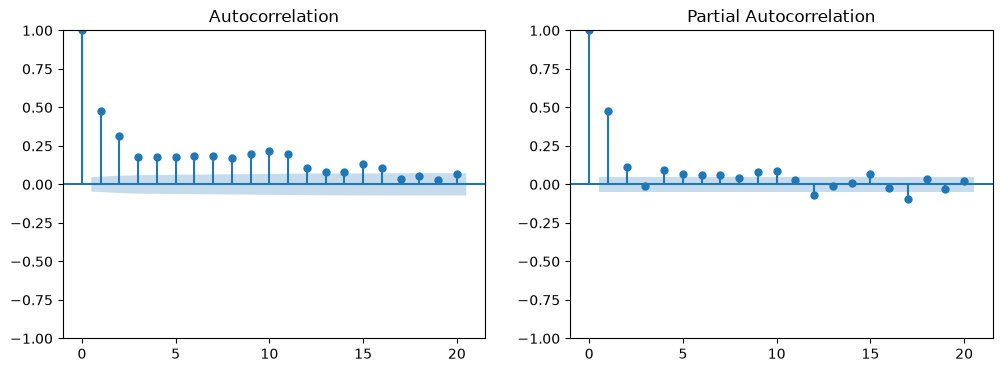

In [121]:
MSFT_sq = MSFT_r ** 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tsaplots.plot_acf(MSFT_sq, lags=20, ax=ax[0])
tsaplots.plot_pacf(MSFT_sq, lags=20, ax=ax[1])
plt.show()

In [128]:
tabla_resumen = evaluate_volatility_models(MSFT_r, max_arch_p=2)
print(tabla_resumen.to_string(index=False))

    Modelo  Todos los Parametros Significativos (<0.05)  ARCH-LM P-value  Homocedastica (>0.05)                                                           P-values de los Parametros del Modelo
   ARCH(1)                                         True           0.0000                  False                                                     mu: 0.0003, omega: 0.0000, alpha[1]: 0.0000
   ARCH(2)                                         True           0.0030                  False                                   mu: 0.0011, omega: 0.0000, alpha[1]: 0.0001, alpha[2]: 0.0002
GARCH(1,1)                                        False           0.9127                   True                                    mu: 0.0004, omega: 0.0600, alpha[1]: 0.0005, beta[1]: 0.0000
GARCH(1,2)                                        False           0.9142                   True                   mu: 0.0004, omega: 0.0592, alpha[1]: 0.0044, beta[1]: 0.0948, beta[2]: 0.6563
GARCH(2,1)                              